# SSW: lower generator learning rate

Continue the shared step-12 checkpoint to step 64 with G learning rate
0.0002 instead of 0.001. D retains learning rate 0.001 and one update per G
update. Architecture, batch size four, dataset noise and evaluation inputs
are unchanged. Compare with Notebook 04. This is one stochastic continuation;
unseeded quantum sampling prevents matched measurement draws.

Quantum and decoder gradient L2 norms are recorded before each G update.
Their magnitudes alone do not establish whether quantum features are useful.
Best checkpoint selection uses validation MMD only; also inspect diversity,
feature spread and logical residual. The selected best can remain step 12.


In [1]:
import json
from pathlib import Path
import numpy as np
import torch
from ssw_quantum_gan import train_run
ROOT = Path.cwd()
torch.set_num_threads(2)
arrays = dict(np.load(ROOT/'ssw_v1.npz', allow_pickle=False))
OUTPUT_DIR = ROOT/'ssw_gan_lower_lr_results'
report = train_run(arrays, OUTPUT_DIR, steps=64, batch_size=4,
    resume=ROOT/'ssw_gan_results/final.pt', discriminator_updates=1,
    generator_lr=0.0002)
assert report['generator_learning_rate'] == 0.0002
assert report['discriminator_learning_rate'] == 0.001
state = torch.load(OUTPUT_DIR/'final.pt', weights_only=True)
assert state['generator_optimizer']['param_groups'][0]['lr'] == 0.0002
assert all(int(s['step']) == 64 for s in state['generator_optimizer']['state'].values())
assert all(int(s['step']) == 64 for s in state['discriminator_optimizer']['state'].values())
assert all(np.isfinite(r[k]) for r in report['losses'] if r['step'] > 12
           for k in ('quantum_gradient_norm', 'decoder_gradient_norm'))
print('Checkpoint rates, optimizer counters and gradient diagnostics verified.')


Restored models, optimizers and RNGs at step 12; validation score verified


Step 12/64: validation MMD²=0.19673


Training step 13/64: {'step': 13, 'discriminator_loss': 0.7409795522689819, 'generator_loss': 0.5040199756622314, 'quantum_gradient_norm': 0.09275242668376864, 'decoder_gradient_norm': 0.5383230459662343, 'discriminator_accuracy': 0.5}


Training step 14/64: {'step': 14, 'discriminator_loss': 0.7341557145118713, 'generator_loss': 0.5143685340881348, 'quantum_gradient_norm': 0.07258473468572263, 'decoder_gradient_norm': 0.5257498098428817, 'discriminator_accuracy': 0.5}


Training step 15/64: {'step': 15, 'discriminator_loss': 0.7178952693939209, 'generator_loss': 0.5263211131095886, 'quantum_gradient_norm': 0.079187253846737, 'decoder_gradient_norm': 0.5231421214061359, 'discriminator_accuracy': 0.5}


...

Training step 62/64: {'step': 62, 'discriminator_loss': 0.7113633751869202, 'generator_loss': 0.6297298669815063, 'quantum_gradient_norm': 0.04226947834108181, 'decoder_gradient_norm': 0.28908474754824837, 'discriminator_accuracy': 0.5}


Training step 63/64: {'step': 63, 'discriminator_loss': 0.705650806427002, 'generator_loss': 0.6296999454498291, 'quantum_gradient_norm': 0.03841605283733875, 'decoder_gradient_norm': 0.2352231210650281, 'discriminator_accuracy': 0.5}


Training step 64/64: {'step': 64, 'discriminator_loss': 0.7123432159423828, 'generator_loss': 0.6359353065490723, 'quantum_gradient_norm': 0.03710133790575025, 'decoder_gradient_norm': 0.21249497910373913, 'discriminator_accuracy': 0.5}


Step 64/64: validation MMD²=0.35917


Checkpoint rates, optimizer counters and gradient diagnostics verified.


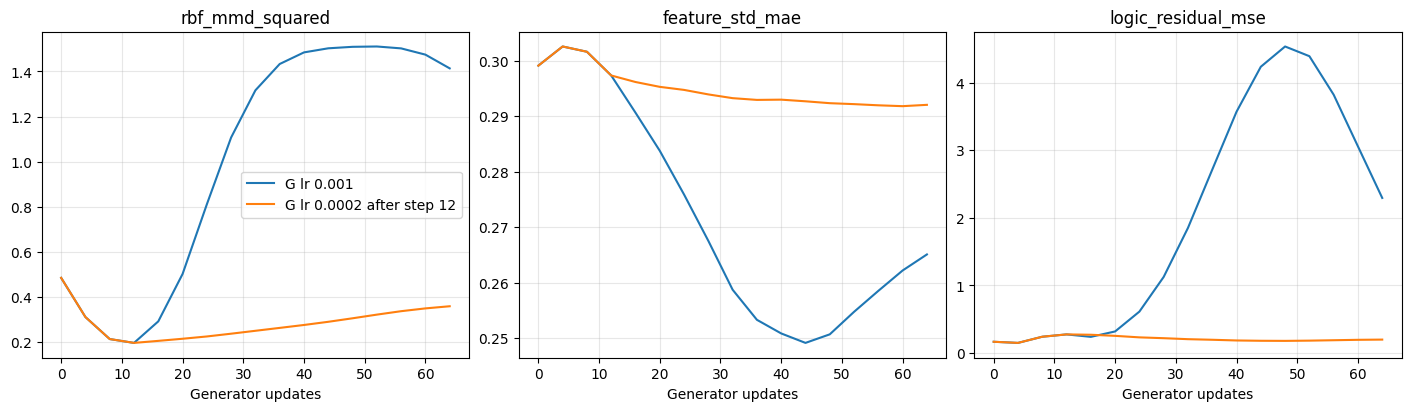

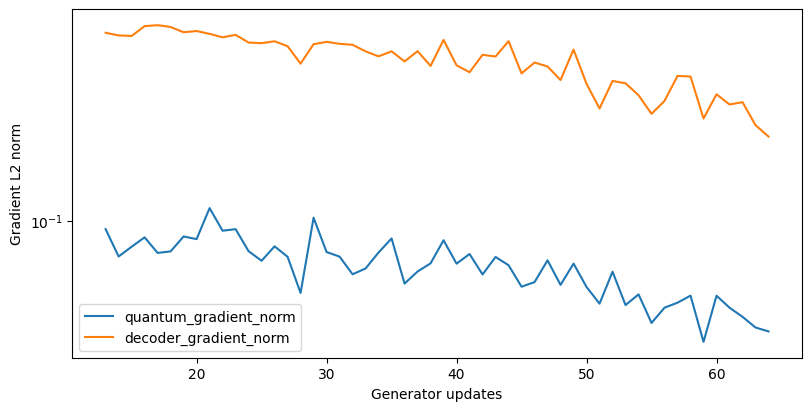

Best step: 12
Final diagnostics: {
  "step": 64,
  "rbf_mmd_squared": 0.35917331815157394,
  "feature_mean_mae": 0.4337509870529175,
  "feature_std_mae": 0.2920307219028473,
  "thresholded_configuration_counts": [
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    11,
    381,
    1,
    4,
    0,
    3,
    0,
    0
  ],
  "covered_configurations": 5,
  "logic_residual_mse": 0.1975586712360382,
  "generated_min": -0.35707664489746094,
  "generated_max": 2.0348122119903564
}


In [2]:
import matplotlib.pyplot as plt
control = json.loads((ROOT/'ssw_gan_longer_results/report.json').read_text())
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for data, label in [(control, 'G lr 0.001'), (report, 'G lr 0.0002 after step 12')]:
    for ax, key in zip(axes, ['rbf_mmd_squared', 'feature_std_mae', 'logic_residual_mse']):
        ax.plot([r['step'] for r in data['history']], [r[key] for r in data['history']], label=label)
        ax.set_title(key); ax.set_xlabel('Generator updates'); ax.grid(alpha=.3)
axes[0].legend()
fig.savefig(OUTPUT_DIR/'control_comparison.png', dpi=150)
plt.show()
rows = [r for r in report['losses'] if r['step'] > 12]
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for key in ['quantum_gradient_norm', 'decoder_gradient_norm']:
    ax.plot([r['step'] for r in rows], [r[key] for r in rows], label=key)
ax.set_yscale('symlog', linthresh=1e-8)
ax.set_xlabel('Generator updates'); ax.set_ylabel('Gradient L2 norm'); ax.legend()
fig.savefig(OUTPUT_DIR/'gradients.png', dpi=150)
plt.show()
print('Best step:', report['best_step'])
print('Final diagnostics:', json.dumps(report['history'][-1], indent=2))
